# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución
## GRUPO: Ax=b

# Integrantes
* Jano Bayarsky
* Ivan Flores

Importamos los módulos que vamos a utilizar:

In [22]:

from matplotlib import pyplot as plt
import cv2
import numpy as np
from alc import *
import pandas as pd

# Ejercicios:

### Ejercicio 1 - DLT ecuaciones formales

- Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

**Respuesta:**

Se busca resolver el sistema $Qm=0$.

Como $Q\in \mathbb{R}^{2n\times 12}$, necesitamos que $12 = \dim\operatorname{Nu}(Q) + \operatorname{rango}(Q)$ (por teorema de la dimensión).
Como se quiere que las soluciones estén a menos de un factor de escala, se pide que $\dim\operatorname{Nu}(Q) = 1$.
Despejando, se obtiene que el rango de $Q$ debe ser $11$.

Para tener un rango $11$, se requiere que la cantidad de puntos sea al menos $6$, ya que cada punto puede aportar a lo sumo dos al rango, y como $n\ge 6 \Rightarrow 2n\ge 12 \ge 11$.

Supongamos que existe un plano $ax+by+cz-d=0$ que contiene a todos los puntos. Entonces existe $v=(a,b,c,-d)\neq0$ tal que $v^\top P_i=0$ para todo $i$ (evaluar cada punto en la ecuación del plano la verifica). Por lo tanto, los vectores $(v,0,0)$ y $(0,v,0)$ de $\mathbb{R}^{12}$ cumplen $Qm=0$ y están en el núcleo de $Q$, con lo que $\dim\operatorname{Nu}(Q)>1$. Entonces los puntos no deben ser coplanares.

Los puntos de un mismo plano aportan en total a lo sumo $8$ al rango de $Q$, sin importar cuántos sean (los primeros $4$ aportan $2$ cada uno y los siguientes nada). Cada punto fuera de ese plano aporta a lo sumo $2$. Para llegar a rango $11$ hacen falta entonces al menos $2$ puntos fuera del plano, ya que $8+2=10<11$ pero $8+2+2=12\ge 11$. Por lo tanto, con $6$ puntos, a lo sumo $4$ pueden estar en un mismo plano.

- Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

**Respuesta:**

Queremos minimizar $\|Qm\|_2^2$, sujeto a $\|m\|_2 = 1$.

Calculo la SVD de $Q = U \Sigma V^\top$. Entonces $\|Qm\|_2^2 = \|U \Sigma V^\top m\|_2^2$. Como $U$ es ortogonal, esto es igual a $\|\Sigma V^\top m\|_2^2$. Renombrando al vector $V^\top m = y$, se tiene $\|\Sigma y\|_2^2$, y el vector $\Sigma y$ es igual a $(\sigma_1 y_1, \sigma_2 y_2, \dots, \sigma_{12} y_{12})$. Entonces

$$\|\Sigma y\|_2^2 = (\sigma_1 y_1)^2 + \dots + (\sigma_{12} y_{12})^2.$$

Cada $\sigma_i$ es mayor o igual que $\sigma_{12}$, así que esa suma es mayor o igual que

$$\sigma_{12}^2 \,(y_1^2 + y_2^2 + \dots + y_{12}^2) = \sigma_{12}^2 \|y\|_2^2.$$

Como $y = V^\top m$ y $V$ es ortogonal, $\|y\|_2^2 = \|m\|_2^2 = 1$ (lo pedimos antes de calcularlo). Recapitulando, llegamos a que

$$\|Qm\|_2^2 \ge \sigma_{12}^2 .$$

Para ver que esa cota se alcanza, volvemos a que $\|Qm\|_2^2 = \|\Sigma y\|_2^2$. Si tomamos $y = (0,0,\dots,1)$, entonces $\|\Sigma y\|_2^2 = \|(0,0,\dots,\sigma_{12})\|_2^2 = \sigma_{12}^2$. Recuperando la información original, $y = e_{12} = V^\top m$. Como $V^\top$ es ortogonal, $m = V e_{12}$, que es igual a tomar la última columna de $V$.

En conclusión, para hallar $m$, solamente basta con elegir la última columna de $V$, de la SVD de $Q$.

### Ejercicio 2 - Calibración con puntos 3D
Implementación de funciones:

a)

In [23]:
det_corners = np.loadtxt('Archivos/calib/3d/detected_corners.txt')
X = det_corners[:,0::2]
Y = det_corners[:,1::2]
real_corners = np.loadtxt('Archivos/calib/3d/p_W_corners.txt',delimiter=',')

In [24]:
def obtenerQ3d(imgPts, objPts):
    n = len(objPts)
    uv = np.asarray(imgPts).reshape(n, 2)
    Q = np.zeros((n*2,12))    
    
    for i in range(n):  
        P = np.append(objPts[i], 1)
        u , v = uv[i]
        Q[2*i,0:4] = P
        Q[2*i,8:12] = -u*P
        
        Q[2*i+1,4:8] = P
        Q[2*i+1,8:12] = -v*P
    
    return Q

b)

In [25]:
k = 0
objPts = real_corners.copy()
imgPts = np.column_stack((X[k], Y[k]))  # (12, 2): píxeles (u, v) de la imagen k

Q = obtenerQ3d(imgPts, objPts)
print(objPts.shape, imgPts.shape, Q.shape)

(12, 3) (12, 2) (24, 12)


In [26]:
def resolverDLT3D(Q):
    U, sigma, V = svd_reducida(Q)
    m = V.T[-1] #ultima fila de V traspuesta, seria la ultima columna de V
    M = m.reshape(3,4)
    return M

c) y d)

In [27]:
def devolverMatricesCalibracion3d(M, misma_focal=False, sin_skew=False):
    J = np.array([
    [0, 0, 1],
    [0, 1, 0],
    [1, 0, 0]
    ])

    A = M[:,:3].copy()
    b = M[:,3].copy()
    B = multiplicarMatrices(J,multiplicarMatrices(A.T,J))

    Q, R = QR_con_GS(B)

    K = multiplicarMatrices(J,multiplicarMatrices(R.T,J))
    R_hat = multiplicarMatrices(J,multiplicarMatrices(Q.T,J))

     # Ajustar signos de la diagonal de K
    D = np.diag(np.sign(np.diag(K)))

    K = multiplicarMatrices(K, D) # para que quede positiva
    R_hat = multiplicarMatrices(D, R_hat) # lo mismo

    # Normalizar K[2,2] = 1
    escala = K[2, 2]
    K = K / escala
    b = b / escala
    
    t = res_tri(K,b)
    if misma_focal:
        f = (K[0,0]+K[1,1])/2 # tomo la media para no alejarme de sus valores originales
        K[0,0] , K[1,1] = f
    if sin_skew:
        K[0,1] = 0
    

    return R_hat, t, K    

Ejercicio de calibración de puntos 3D:

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$

# Falta usar las funciones para la calibración

### Ejercicio 3 - Calibración con puntos coplanares
Implementación de funciones:

Item 2

In [28]:
#copy paste casi igual de la 3D
def obtenerQ2d(imgPts, objPts): 
    n = len(objPts)
    uv = np.asarray(imgPts).reshape(n, 2)
    Q = np.zeros((n*2,9))    
    
    for i in range(n):  
        P = np.append(objPts[i], 1)
        u , v = uv[i]
        Q[2*i,0:3] = P
        Q[2*i,6:9] = -u*P
        
        Q[2*i+1,3:6] = P
        Q[2*i+1,6:9] = -v*P
    
    return Q

def resolver2D(Q):
    U, sigma, V = svd_reducida(Q)
    m = V.T[-1] #ultima fila de V traspuesta, seria la ultima columna de V
    return m.reshape(3,3)

### Item 3

In [29]:
def calcularV(H, i, j):
    v = np.array([
        H[0,i]*H[0,j],
        H[0,i]*H[1,j] + H[1,i]*H[0,j],
        H[1,i]*H[1,j],
        H[2,i]*H[0,j] + H[0,i]*H[2,j],
        H[2,i]*H[1,j] + H[1,i]*H[2,j],
        H[2,i]*H[2,j]
    ])
    return v

def armarA(Hlst):
    
    n = len(Hlst)
    A = np.zeros((2*n,6))
    j = 0
    for H in Hlst:
        v12 = calcularV(H,0,1)
        v11 = calcularV(H,0,0)
        v22 = calcularV(H,1,1)
        V = np.array([v12,v11-v22])
        
        A[2*j : 2*j+2,:] = V
        j = j + 1
    
    return A

### Item 4

In [30]:
def calcularMatrizK2D(A):
    U, S, V = svd_reducida(A, tol=1e-20)
    b = V[:,-1] # la transpongo para quedarme con la ultima columna de V
                 # el cual me da el valor singular minimo
    B = np.array([
                [b[0],b[1],b[3]],
                [b[1],b[2],b[4]],
                [b[3],b[4],b[5]]
                ])

    # Intentar corregir el signo de B
    
    #if np.all(autovalores < 0):
    #    B = -B
    autovalores = np.linalg.eigvalsh(B)

    if np.all(autovalores < 0):
        B = -B

    L = calculaCholesky(B)

    K = np.linalg.inv(L.T)
    K = K / K[2,2]
    return K

### Item 5

In [31]:
def obtenerPose2D(Hj,K):
    K_inv = inversa(K)
    lamb = 1/ norma(productoPunto(K_inv,Hj[:,0]),2)
    r1 = lamb*(productoPunto(K_inv,Hj[:,0]))
    r2 = lamb*(productoPunto(K_inv,Hj[:,1]))
    r3 = prodVectorial(r1,r2)
    R_t = np.array([r1,r2,r3])
    R = R_t.T

    tj = lamb*(productoPunto(K_inv,Hj[:,2]))

    return R, tj

Ejercicio de calibración de puntos coplanares:

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.

a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

# Falta usar las funciones para la calibración

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

Calculamos la distancia de Enzo al arco en el momento de patear:

In [32]:
def distGolEnzo(pt,H):
    p = np.array([pt[0],pt[1],1])
    U,V, W  = calcularAx(inversa(H), p)
    x, y = U / W, V/W
    return np.sqrt((105-x)**2+(34-y)**2)

In [33]:
img = cv2.imread("Archivos/futbol/test-gol-enzo.png")
if img is None:
    raise FileNotFoundError("No se pudo leer la imagen, revisá la ruta")

imgPts =  np.array([
            [510, 320],  
            [651, 184],  
            [383, 175],  
            [842, 189],  
            [196, 171],  
            [865, 252],  
            [156, 233]   
        ])

objPts = np.array([[94,34],
                   [105,30.34],
                   [105,37.66],
                   [105,24.84],
                   [105,43.16],
                   [99.5,24.84],
                   [99.5,43.16]
                   ])

In [34]:
Q = obtenerQ2d(imgPts,objPts)
H = resolver2D(Q)

pieEnzo = (807,540)

dist = distGolEnzo(pieEnzo,H)
print(dist)

23.04949249926027


Trazamos un círculo al rededor de los jugadores argentinos:

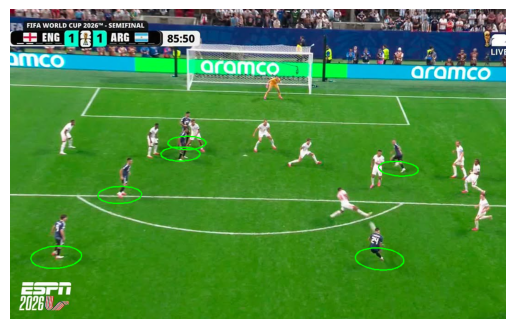

In [35]:
#Ubicar jugadores argentinos 
posJugadores = np.array([
    [101, 539],
    [239, 404],
    [371, 315],
    [385, 291],
    [804, 543],
    [845, 347]
])

def proyectar(H, x, y):
    q = calcularAx(H , np.array([x, y, 1.0]))
    return q[0] / q[2], q[1] / q[2]       # (u, v) en píxeles

H_inv = inversa(H)

img = cv2.imread("Archivos/futbol/test-gol-enzo.png")
assert img is not None, "no se encontró la imagen"

def dibujar_circulo(img, H, cx, cy, color=(0, 255, 0), grosor=2):
    t = np.linspace(0,2*np.pi, 60)
    pts = [proyectar(H,cx+1*np.cos(a),cy+1*np.sin(a))for a in t]
    pts = np.array(pts,dtype=np.int32)
    cv2.polylines(img,[pts],True,color,grosor)

for pos in posJugadores:
    U,V = proyectar(H_inv,pos[0],pos[1])
    dibujar_circulo(img,H,U,V)


plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.

Para construir H necesitamos elegir al menos 4 puntos, de forma que ninguna de las filas de la matriz sea linealmente dependiente de las demás. 

Elegimos 9 puntos con una separacion considerable entre sí. Los puntos reales de la cancha se eligieron tomando como referencia los datos del Estadio Azteca, y los puntos de la imagen los seleccionamos utilizando Paint, poniendo el cursor sobre el pixel buscado y registrando su valor.

En coordenadas reales, el area grande del lado derecho está en x=88,5; el area grande en x=99,5.
Desde el medio de la cancha (respecto a y), el arco tiene 3,66 mts para cada lado; 9,16 el área chica; y 20,16 el área grande.
La linea lateral superior está en y=0; la linea de fondo derecha en x=105.

In [36]:
puntos_cancha = np.array([
    [105,0],
    [105,(68/2)-(40.32/2)],
    [105,(68/2)-(18.32/2)],
    [105,(68/2)-(7.32/2)],
    [105-5.5,(68/2)-(18.32/2)],
    [105-5.5,(68/2)+(18.32/2)],
    [105-16.5,(68/2)-(40.32/2)],
    [105-16.5,(68/2)+(40.32/2)],

])

puntos_imagen = np.array([
    [1306, 235],
    [1388, 311],
    [1475, 387],
    [1524, 433],
    [1231, 391],
    [1365, 575],
    [735, 317],
    [736, 755],
])

Para obtener la matriz H, se debe descomponer Q en SVD, y tomar la última columna de V (o última fila de V traspuesta), que será igual a la matriz h (los elementos de la matriz H puestos como vector)

In [37]:
Q = obtenerQ2d(puntos_imagen,puntos_cancha)
H = resolver2D(Q)

Verificamos que esté bien calculada con algunos puntos:

In [38]:
puntos_cancha_aux = []

for punto in puntos_cancha:
    punto = np.append(punto, 1)
    puntos_cancha_aux.append(punto)

puntos_cancha_aux = np.array(puntos_cancha_aux)

for punto in puntos_cancha_aux:
    print (calcularAx(H,punto))

[-5.48191519e-01 -9.89385868e-02 -4.19587686e-04]
[-5.09606911e-01 -1.13918103e-01 -3.66892818e-04]
[-4.78939953e-01 -1.25823788e-01 -3.25011058e-04]
[-4.63606475e-01 -1.31776631e-01 -3.04070179e-04]
[-3.98152003e-01 -1.26256768e-01 -3.23926969e-04]
[-3.47077580e-01 -1.46085145e-01 -2.54174803e-04]
[-0.26724306 -0.11521704 -0.00036364]
[-0.15483472 -0.15885679 -0.00021012]


In [39]:
# Como queremos que la ultima coord del punto de la imagen sea 1, dividimos por ese valor
for punto in puntos_cancha_aux:
    punto_im = calcularAx(H,punto)
    punto_im = punto_im / punto_im[-1]
    print (punto_im)

[1.30650049e+03 2.35799548e+02 1.00000000e+00]
[1.38898034e+03 3.10494231e+02 1.00000000e+00]
[1.47361125e+03 3.87136945e+02 1.00000000e+00]
[1.52466933e+03 4.33375714e+02 1.00000000e+00]
[1.22914126e+03 3.89769237e+02 1.00000000e+00]
[1.36550742e+03 5.74742828e+02 1.00000000e+00]
[734.90995498 316.84321708   1.        ]
[736.87006036 756.01138018   1.        ]


Los pixeles obtenidos son bastante cercanos a los de la imagen.

El pie del penúltimo jugador del otro equipo está en el pixel (827,327) aproximadamente. Lo pasamos a Coordenadas del mundo real con la inversa de H, y tomamos el punto que está a altura 0 con el mismo valor de x, y entre ellos trazamos la linea

In [40]:
inv_H = inversa(H)
pixel_pie = [827,327,1]
posicion_pie = calcularAx(inv_H,pixel_pie)
print(posicion_pie)

[-253871.00790408  -43539.9064929    -2797.09056761]


Como queremos que la ultima coord del punto de la imagen sea 1, dividimos por ese valor

In [41]:
posicion_pie = posicion_pie / posicion_pie[-1]
print(posicion_pie)

[90.76252691 15.56614112  1.        ]


El pie está en x = 90,76. 
Para trazar una recta paralela a la linea de fondo, buscamos el pixel correspondiente a la posición del mundo real (90.76,0), que es la posicion correspondiente al mismo valor de x sobre la linea lateral superior. Usamos la homografía para encontrar este valor.

In [42]:
segundo_punto = calcularAx(H,[90.76,0,1])
print(segundo_punto)
segundo_punto = segundo_punto / segundo_punto[-1]
print(segundo_punto)

[-0.33902417 -0.10005961 -0.00041678]
[813.43503905 240.07725601   1.        ]


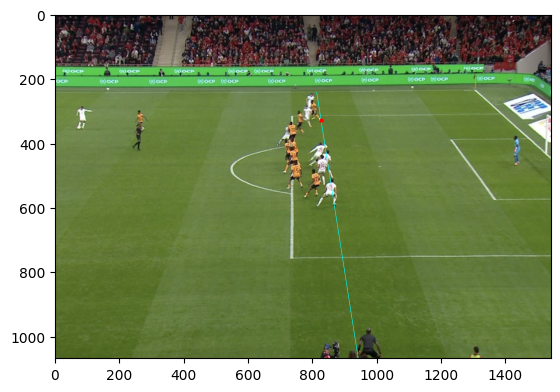

In [61]:
u1, v1, _ = pixel_pie
u2, v2, _ = segundo_punto

fuera_de_juego = cv2.imread('Archivos/futbol/test-fuera-de-juego.png')
fuera_de_juego = cv2.cvtColor(fuera_de_juego, cv2.COLOR_BGR2RGB)
plt.imshow(fuera_de_juego)

m = (v2 - v1) / (u2 - u1)
b = v1 - m * u1
alto_img, ancho_img = fuera_de_juego.shape[0], fuera_de_juego.shape[1]

v_fin = alto_img - 1
u_fin = u2 + (v_fin - v2) / m

plt.scatter(u1,v1, color="red", s=4, zorder=5)

plt.plot([u2, u_fin], [v2, v_fin], color="cyan", linewidth=0.4)

plt.xlim(0, ancho_img)
plt.ylim(alto_img, 0)  

plt.show()

Trazamos la linea de offside, marcamos con un punto rojo el apoyo del pie del jugador del otro equipo sobre ella.
Se puede ver que al menos dos jugadores del equipo blanco están adelantados: El de abajo de todo tiene casi medio cuerpo adelantado, y hay otro que tiene la pierna adelantada. Hay otro que está sobre la linea, pero parece ser que está habilitado ya tiene en brazo adelantado unicamente

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

In [46]:
df = pd.read_csv('Archivos/salguero/world_img_pts.csv', sep=";")
display(df)
display(df.shape)
data = df.values

,pts,X,Y,Z,u_0,v_0,u_1,v_1,u_2,v_2,u_3,v_3
0,6,-4.0,3,0.0,281,474,255,490,469,581,446,563
1,36,4.0,0,0.0,889,521,1071,577,1147,653,1118,621
2,40,6.5,3,0.1,1139,493,1403,550,1425,625,1396,590
3,41,-5.0,14,0.1,418,385,437,377,627,485,600,466
4,42,-5.0,76,0.1,833,262,997,227,1094,357,1064,331


(5, 12)

Como tenemos únicamente 5 puntos para realizar la calibración, no se puede realizar la de puntos 3D: Vamos a pensar el problema como uno de puntos coplanares. De esta forma se van a tener más que 4 puntos, que es lo necesario para realizar este tipo de calibración.

Al tener varias tomas distintas, podemos aprovechar esta información para calcular distintos Hj para armar la matriz A, y con ella la matriz K. Habiendo obtenido la matriz K, y para una vista Hj determinada, podemos calcular el valor de la pose de la cámara (los parámetros Rj y tj).

In [47]:
XY = data[:, 1:3]
u = data[:, 4:12:2]
v = data[:, 5:12:2]

In [48]:
lista_H = []
for i in range(4):
    ui = u[:,i]
    vi = v[:,i]

    objPts = XY
    imgPts = np.column_stack((ui, vi))

    Q = obtenerQ2d(imgPts, objPts)
    Hj = resolver2D(Q)
    lista_H.append(Hj)

A = armarA(lista_H)
K = calcularMatrizK2D(A).T
print(K)

[[ 2.78278008e+03  1.77028087e+04  8.04474792e+05]
 [ 1.52312018e-14  2.13055734e+02  4.16794551e+04]
 [ 1.16204848e-19 -0.00000000e+00  1.00000000e+00]]


b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

In [50]:
puntos_primera_imagen = np.loadtxt('Archivos/salguero/gs_10_09_point_correspondences_v5.txt',delimiter='	')

En este caso todos los z valen 0, asi que nuevamente se usa el modelo de puntos coplanares.

In [51]:
XY, uv = (
    puntos_primera_imagen[1:3,:],
    puntos_primera_imagen[4:,:],

)

XY = XY.T
uv = uv.T

print(XY.shape)
print(uv.shape)

(51, 2)
(51, 2)


Calculamos la matriz Hj específica para esta toma, y se aprovecha el calculo de los parámetros intrínsecos (K) en el item anterior para estimar Rj y tj.

In [52]:
Q = obtenerQ2d(uv,XY)
Hj = resolver2D(Q)
Rj,tj = obtenerPose2D(Hj, K)

# Falta reproyectar

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

Tenemos 46 tomas, y todas tienen la misma posición de la cámara, y comparten el parámetro intrínseco. Elegimos tratarla como se fuera una única imagen que tiene distintos puntos. 

El segundo final es el 52.546, y el inicial el 47,351. El lapso es de 5,195 segundos. Vamos a usar 6 tomas distribuidas de forma uniforme entre la primera y la ultima para tener un frame cada un segundo aproximadamente, ya que se asume que la separación temporal entre una toma y la siguiente es similar para todas.

Se eligen las imágenes 1,10,19,28,37,46.

Im1: img_10_18_47_351.jpg

Im10: img_10_18_48_350.jpg

Im19: img_10_18_49_582.jpg

Im28: img_10_18_50_534.jpg

Im37: img_10_18_51_563.jpg

Im46: img_10_18_52_546.jpg


In [53]:
señora_px = np.array([[418,501],[544,495],[695,490],[814,490],[909,489],[989,489]])
taxi_px = np.array([[933,267],[900,283],[835,307],[756,350],[612,419],[299,577]])
camioneta_px = np.array([[995,258],[988,270],[972,288],[941,317],[891,361],[788,445]])
segundos = np.array([47.351,48.350,49.582,50.534,51.563,52.546])

Nuevamente los u,v se seleccionaron mediante Paint.

En el b se calculó la pose de la cámara para la imagen img_10_18_47_351.jpg, que es la misma que la primera de estas 6. Por lo tanto ya se tiene K,Rj y tj para esa imagen y las otras 5.

Se utiliza esta información para construir H, y pasar de las coordenadas en pantalla a las coordenadas reales, así calculamos las velocidades.
Las mismas serán entre los intervalos 1-10, 10-19, 19-28, 28-37, 37-46. Cada una se va a calcular como la norma 2 de (xf,yf)-(xi,yf) (la variación de la distancia), y dividimos por el segundo final menos el segundo inicial. Vamos a tomar la velocidad que se pide en la consigna como el promedio de estas 5 velocidades.

In [54]:
np.set_printoptions(suppress=True, precision=10)

def obtener_velocidad(puntos_px, H, segs):
    inv_H = inversa(H)
    # Pasamos de puntos de la imagen a puntos reales, y agregamos 1 al final
    puntos_reales = np.array([calcularAx(inv_H, np.append(punto, 1)) for punto in puntos_px])
    puntos_reales = puntos_reales / puntos_reales[:,2:3]

    # Calculamos el vector desplazamiento entre un punto y el siguiente, para todos los puntos
    desplazamientos = np.diff(puntos_reales, axis=0)

    # Pasamos los vectores desplazamiento a un número a traves de la norma
    metros_recorridos = norma(desplazamientos.T, 2)

    # Calculamos la variación de tiempo entre una imagen y la otra, para todas las imagenes
    variaciones_tiempo = np.diff(segs)

    # Calculamos la velocidad como la distancia recorrida entre el tiempo transcurrido
    velocidades = metros_recorridos / variaciones_tiempo

    # Calculamos la velocidad promedio como la suma de todas las velocidades dividido la cantidad de muestras
    promedio_velocidad = sum(velocidades) / len(velocidades)

    return promedio_velocidad

velocidad_promedio_señora = obtener_velocidad(señora_px, Hj, segundos)
velocidad_promedio_taxi = obtener_velocidad(taxi_px, Hj, segundos)
velocidad_promedio_camioneta = obtener_velocidad(camioneta_px, Hj, segundos)

print(velocidad_promedio_señora,velocidad_promedio_taxi,velocidad_promedio_camioneta)

1.3504619518052614 14.225734473713345 14.440128365434475


Las tres velocidades están en m/s, pasamos a km/h para entender mejor esta información. 

Sabemos que km/h = m/s x 3,6

In [55]:
velocidad_promedio_señora = velocidad_promedio_señora * 3.6
velocidad_promedio_taxi = velocidad_promedio_taxi * 3.6
velocidad_promedio_camioneta = velocidad_promedio_camioneta * 3.6

print(velocidad_promedio_señora,velocidad_promedio_taxi,velocidad_promedio_camioneta)

4.861663026498941 51.21264410536804 51.984462115564114


### Ejercicio 6 - Aterrizaje suave
Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

a)

In [56]:
centro_real = 0.0,0.0
sup_izq_real = -0.175,0.3
sup_der_real = 0.175,0.3
inf_der_real = 0.175,-0.3
inf_izq_real = -0.175,-0.3
UV = np.array([centro_real,sup_izq_real,sup_der_real,inf_der_real,inf_izq_real])

centro_px = 526,1007
sup_izq_px = 402,1097
sup_der_px = 392,944
inf_der_px = 644,913
inf_izq_px = 656,1061
uv = np.array([centro_px,sup_izq_px,sup_der_px,inf_der_px,inf_izq_px])

display(UV)
display(uv)

array([[ 0.   ,  0.   ],
       [-0.175,  0.3  ],
       [ 0.175,  0.3  ],
       [ 0.175, -0.3  ],
       [-0.175, -0.3  ]])

array([[ 526, 1007],
       [ 402, 1097],
       [ 392,  944],
       [ 644,  913],
       [ 656, 1061]])

In [58]:
Q = obtenerQ2d(uv, UV)
H = resolver2D(Q)
K = np.loadtxt("Archivos/heli/K.csv", delimiter=";")
R,t = obtenerPose2D(H, K)
np.set_printoptions(suppress=True, precision=8)

# A partir de los de abajo hay que revisar

b)

In [59]:
def calculoLambdaMu(I0,J0):
    a = norma(J0,2)**2 - norma(I0,2)**2
    b = -2*multiplicarMatrices(I0.T,J0)
    r = np.sqrt(a**2+b**2)
    lamb = np.sqrt((r+a)/2)
    
    mu  = np.sqrt((r-a)/2)
    if b < 0:
        mu = -mu
    return lamb, mu

c)

In [60]:
def calcularSalidaPOSIT(Is, Js, fx, m0, M0):
    Z0 = fx / norma(Is,2)
    i = Is / norma(Is,2)
    j = Js / norma(Js,2)

    k = np.array([
    i[1]*j[2] - i[2]*j[1],
    i[2]*j[0] - i[0]*j[2],
    i[0]*j[1] - i[1]*j[0]
    ])

    R = np.array([i,j,k])

    x0 = m0[0]
    y0 = m0[1]

    X0 = (Z0 / fx)*x0 
    Y0 = (Z0/fx)*y0

    T = np.array([X0,Y0,Z0])
    
    t = T - multiplicarMatrices(R,M0).reshape(3)

    return i, j, k, Z0, R, T

d)

e)

Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

f)